# J3 — Généralisation et régularisation

Objectif : suivre les performances sur train et validation, observer le sur-apprentissage et comparer plusieurs méthodes de régularisation.

## Travaux demandés
- [x] D1 — comparer le modèle sans régularisation et avec L2
- [x] D1 — comparer le dropout à plusieurs taux
- [x] D1 — ajouter early stopping
- [x] D2 — analyser les hyperparamètres et le sur-apprentissage
- [x] Évaluer une seule fois le modèle retenu sur le test

Le jeu de test n’est pas utilisé pour choisir les hyperparamètres.


## D1 — Effet de la pénalisation L2
On ajoute `λ/2 · Σ||W||²` à l’objectif et `λW` aux gradients des poids. Les biais ne sont pas pénalisés. Les losses affichées restent les BCE sans pénalité, afin de comparer la qualité prédictive sur train et validation.


λ=0: train loss=0.0800, val loss=0.0825, val accuracy=0.967, ||W||=8.389
λ=0.0001: train loss=0.0801, val loss=0.0826, val accuracy=0.967, ||W||=8.276
λ=0.001: train loss=0.0827, val loss=0.0855, val accuracy=0.963, ||W||=7.382
λ=0.01: train loss=0.1178, val loss=0.1215, val accuracy=0.953, ||W||=4.949
λ=0.1: train loss=0.3356, val loss=0.3253, val accuracy=0.887, ||W||=1.979


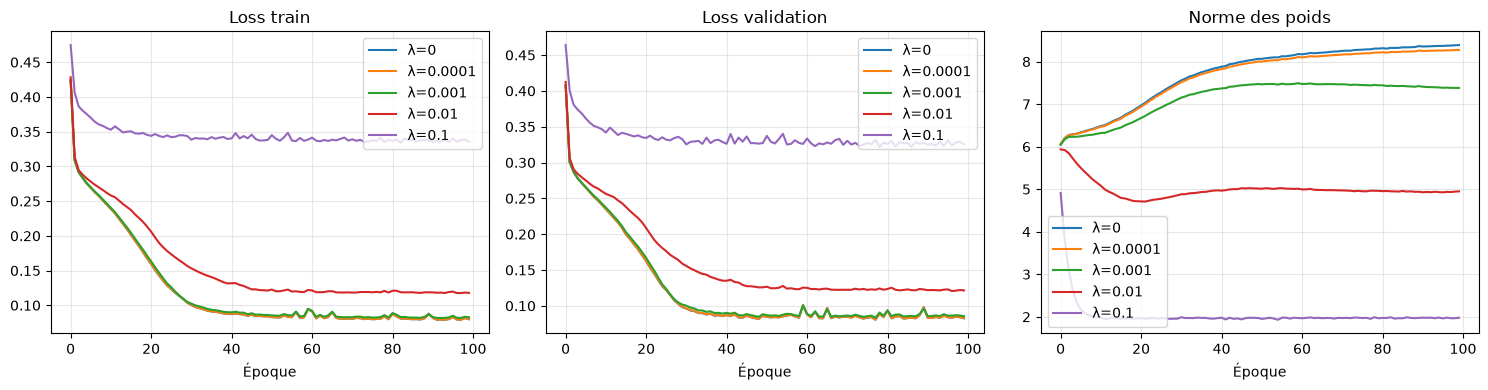

In [1]:
from data import SEED, generate_data, split_data, standardize_data
from model import init_params
from train import train_model
from plots import plot_regularization_comparison

X, y = generate_data(seed=SEED)
X_train, X_val, X_test, y_train, y_val, y_test = split_data(X, y, seed=SEED)
X_train, X_val, X_test, mean, std = standardize_data(X_train, X_val, X_test)
y_train = y_train.reshape(-1, 1)
y_val = y_val.reshape(-1, 1)
y_test = y_test.reshape(-1, 1)

l2_values = [0, 1e-4, 1e-3, 1e-2, 1e-1]
l2_histories = {}
l2_models = {}
for coefficient in l2_values:
    label = f"λ={coefficient:g}"
    params, history = train_model(
        X_train, y_train, X_val, y_val, init_params(seed=SEED),
        optimizer="momentum", learning_rate=0.1, epochs=100,
        batch_size=32, seed=SEED, optimizer_kwargs={"beta": 0.9},
        l2_coefficient=coefficient,
    )
    l2_histories[label] = history
    l2_models[label] = params
    print(
        f"{label}: train loss={history['train_loss'][-1]:.4f}, "
        f"val loss={history['val_loss'][-1]:.4f}, "
        f"val accuracy={history['val_accuracy'][-1]:.3f}, "
        f"||W||={history['parameter_norm'][-1]:.3f}"
    )

plot_regularization_comparison(l2_histories)


### Analyse L2
Interpréter l’évolution des losses train/validation et de la norme des poids quand `λ` augmente. Une baisse de la norme montre que les poids sont davantage pénalisés ; elle ne garantit pas à elle seule une meilleure généralisation.

Le graphique confirme que la norme des poids baisse à mesure que `λ` augmente : de `8,389` sans L2 à `1,979` pour `λ=0,1`. Pour `λ ≤ 0,001`, les courbes train et validation restent proches et les losses finales sont similaires. Sur cette grille, `λ=0` donne la meilleure loss validation (`0,0825`), presque identique à `λ=1e-4` (`0,0826`). À partir de `λ=1e-3`, les losses augmentent ; `λ=0,01` ralentit l’apprentissage et `λ=0,1` maintient une loss élevée. Ces grandes valeurs pénalisent trop le modèle et dégradent aussi l’accuracy.

Ici, la L2 ne réduit pas l’écart train/validation de façon utile ; les résultats suggèrent plutôt un sous-apprentissage pour les grandes valeurs de `λ`. Cette conclusion concerne ce split, cette seed et Momentum avec `learning_rate=0,1`. La sélection des valeurs de `λ` s’est faite sur validation ; le test a été réservé à l’évaluation finale.


## D1 — Effet du dropout
Le dropout inversé est appliqué aux deux couches cachées durant l’entraînement. Pendant validation et test, il est désactivé. On compare les taux `0`, `0,2` et `0,5` avec le même split, la même seed et Momentum.


dropout=0: train loss=0.0800, val loss=0.0825, val accuracy=0.967
dropout=0.2: train loss=0.0991, val loss=0.1036, val accuracy=0.957
dropout=0.5: train loss=0.1772, val loss=0.1777, val accuracy=0.893


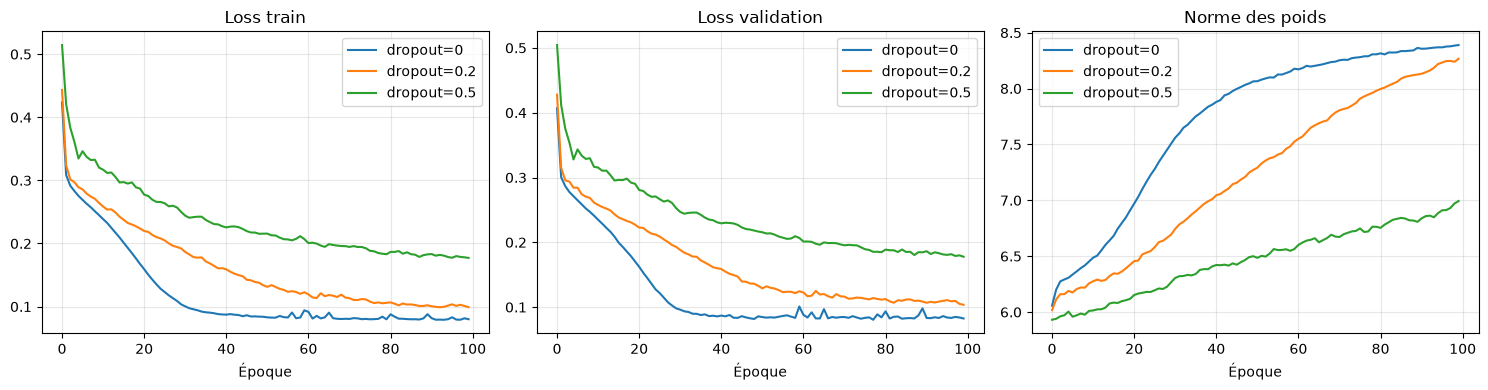

In [2]:
dropout_rates = [0.0, 0.2, 0.5]
dropout_histories = {}
dropout_models = {}
for rate in dropout_rates:
    label = f"dropout={rate:g}"
    params, history = train_model(
        X_train, y_train, X_val, y_val, init_params(seed=SEED),
        optimizer="momentum", learning_rate=0.1, epochs=100,
        batch_size=32, seed=SEED, optimizer_kwargs={"beta": 0.9},
        dropout_rate=rate,
    )
    dropout_histories[label] = history
    dropout_models[label] = params
    print(
        f"{label}: train loss={history['train_loss'][-1]:.4f}, "
        f"val loss={history['val_loss'][-1]:.4f}, "
        f"val accuracy={history['val_accuracy'][-1]:.3f}"
    )
plot_regularization_comparison(dropout_histories)


### Analyse du dropout
Les courbes train et validation baissent pour les trois taux, mais restent proches l’une de l’autre. Sans dropout, les losses finales sont les plus faibles (`0,0800` train, `0,0825` validation). À `0,2`, elles montent à `0,0991` et `0,1036` ; à `0,5`, à `0,1772` et `0,1777`. L’accuracy validation descend respectivement de `0,967` à `0,957` puis `0,893`.

La norme des poids diminue quand le taux de dropout augmente, mais cela ne compense pas la hausse des losses : le réseau apprend moins bien. Dans cette expérience, le dropout ajoute une régularisation excessive pour ce petit réseau. L’écart train/validation reste faible, sans signe net de sur-apprentissage.

La sélection des taux de dropout s’est faite sur validation ; le test a été réservé à l’évaluation finale.


## D1 — Early stopping
On surveille la loss validation. Si elle ne s’améliore pas pendant 15 époques, l’entraînement s’arrête et les paramètres du meilleur epoch sont restaurés. La comparaison utilise le même optimiseur, la même seed et le même budget maximal.


sans arrêt anticipé: époque arrêt=300, meilleure époque=78, loss validation du modèle retourné=0.0872, accuracy=0.970
patience=15: époque arrêt=64, meilleure époque=49, loss validation du modèle retourné=0.0817, accuracy=0.973


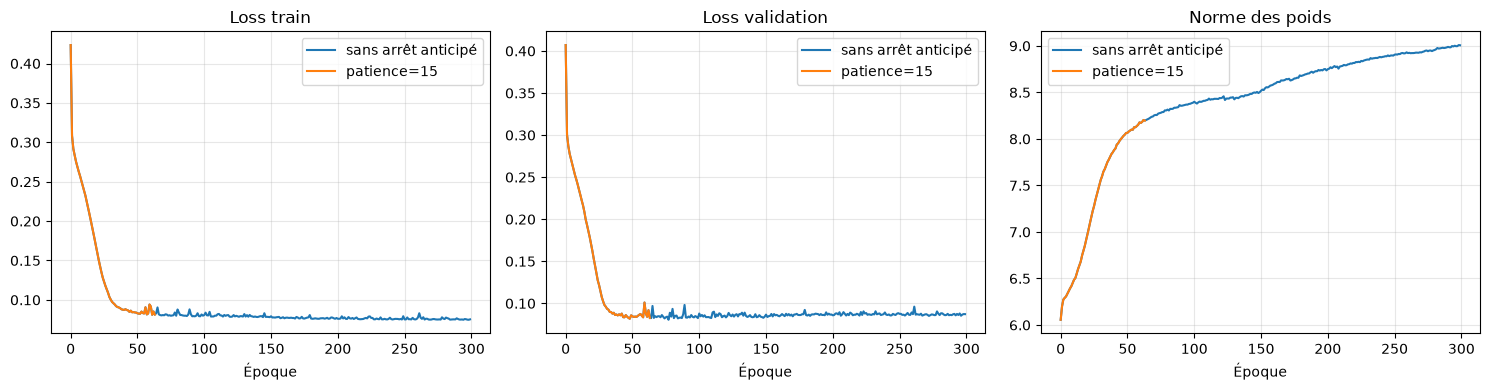

In [3]:
from train import evaluate

early_histories = {}
early_models = {}
for label, patience in (("sans arrêt anticipé", None), ("patience=15", 15)):
    params, history = train_model(
        X_train, y_train, X_val, y_val, init_params(seed=SEED),
        optimizer="momentum", learning_rate=0.1, epochs=300,
        batch_size=32, seed=SEED, optimizer_kwargs={"beta": 0.9},
        patience=patience, min_delta=1e-4,
    )
    early_histories[label] = history
    early_models[label] = params
    metrics = evaluate(X_val, y_val, params)
    print(
        f"{label}: époque arrêt={history['stopped_epoch']}, "
        f"meilleure époque={history['best_epoch']}, "
        f"loss validation du modèle retourné={metrics['loss']:.4f}, "
        f"accuracy={metrics['accuracy']:.3f}"
    )
plot_regularization_comparison(early_histories)


### Analyse de l’early stopping
Avec `patience=15` et `min_delta=1e-4`, l’entraînement s’arrête à l’époque 64 et restaure le modèle de l’époque 49. Sa loss validation est `0,0817` et son accuracy `0,973`. Sans early stopping, l’entraînement va jusqu’à 300 époques et finit à une loss validation de `0,0872`.

Le graphique montre que la loss train continue à baisser légèrement après le meilleur résultat validation, tandis que la loss validation fluctue et que la norme des poids continue d’augmenter sans arrêt anticipé. Cela indique un début de sur-apprentissage. L’early stopping restaure le checkpoint de l’époque 49 ; sans arrêt, le modèle final de l’époque 300 a une loss validation de `0,0872`, malgré un minimum historique à l’époque 78.


## D2 — Sélection finale et évaluation test
Le checkpoint de Momentum à l’époque 49 est sélectionné avec la loss validation. La cellule suivante réentraîne ce modèle de manière reproductible et l’évalue une seule fois sur le test.


In [4]:
selected_params, selected_history = train_model(
    X_train, y_train, X_val, y_val, init_params(seed=SEED),
    optimizer="momentum", learning_rate=0.1, epochs=300,
    batch_size=32, seed=SEED, optimizer_kwargs={"beta": 0.9},
    patience=15, min_delta=1e-4,
)
test_metrics = evaluate(X_test, y_test, selected_params)
print("Meilleur epoch :", selected_history['best_epoch'])
print("Test loss :", test_metrics['loss'])
print("Test accuracy :", test_metrics['accuracy'])


Meilleur epoch : 49
Test loss : 0.059405383598940514
Test accuracy : 0.9866666666666667


### Résultat final J3
Le modèle sélectionné atteint sur le test une BCE de `0,0594` et une accuracy de `0,987` (environ `98,7 %`). Ce résultat est cohérent avec la validation (`0,0817`, accuracy `0,973`) ; les métriques test ont été calculées après la sélection du modèle.
